# JavaScript npm/yarn Package Management

This notebook covers the fundamentals of JavaScript package management using npm and Yarn — from understanding what a package manager is, through everyday install/remove workflows, to advanced topics like scripting, publishing, and Yarn's zero-install architecture.

## Table of Contents

- [Module 01: Package Managers in JavaScript](#Module-01:-Package-Managers-in-JavaScript)
- [Module 02: Managing Packages with npm](#Module-02:-Managing-Packages-with-npm)
- [Module 03: Advanced Tasks with npm](#Module-03:-Advanced-Tasks-with-npm)
- [Module 04: Managing Packages with Yarn](#Module-04:-Managing-Packages-with-Yarn)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

---
## Module 01: Package Managers in JavaScript

_Introduces the concept of package managers, why they exist, and the two-component npm architecture shared by both npm and Yarn._

### Version Compatibility

This material applies to:

- Any version of npm
- Any version of Node.js
- Yarn version 2+

### Course Overview

Topics covered across the course:

- Introduction to package managers
- Basic package management tasks
- Advanced tasks
- Publishing your own package
- Managing packages with Yarn

### What is a Package Manager?

A package manager lets your application consume third-party code — frameworks, state management libraries, date utilities, and so on — without manually downloading and managing those files.

Your application is composed of:
- **Code you write** — the business logic unique to your project
- **Third-party packages** — reusable libraries fetched and managed by the package manager

The package manager handles downloading, versioning, and linking those dependencies into your project.

### Considerations with Third-Party Code

Using external packages introduces three cross-cutting concerns:

- **Download** — where do packages come from, and how do you control which source is trusted?
- **Security** — packages can contain malicious code; knowing who publishes what matters
- **Versioning** — breaking changes in a dependency can break your project; pinning and lockfiles mitigate this

### npm Architecture

npm consists of two distinct components:

- **npm registry** — a central repository (hosted at registry.npmjs.org by default) that stores published packages
- **npm client** — the CLI tool (`npm`) installed on your machine that reads `package.json`, resolves the dependency graph, and fetches packages from the registry

**Yarn shares the same registry** — it is an alternative client that reads from the same npm repository, not a separate package ecosystem.


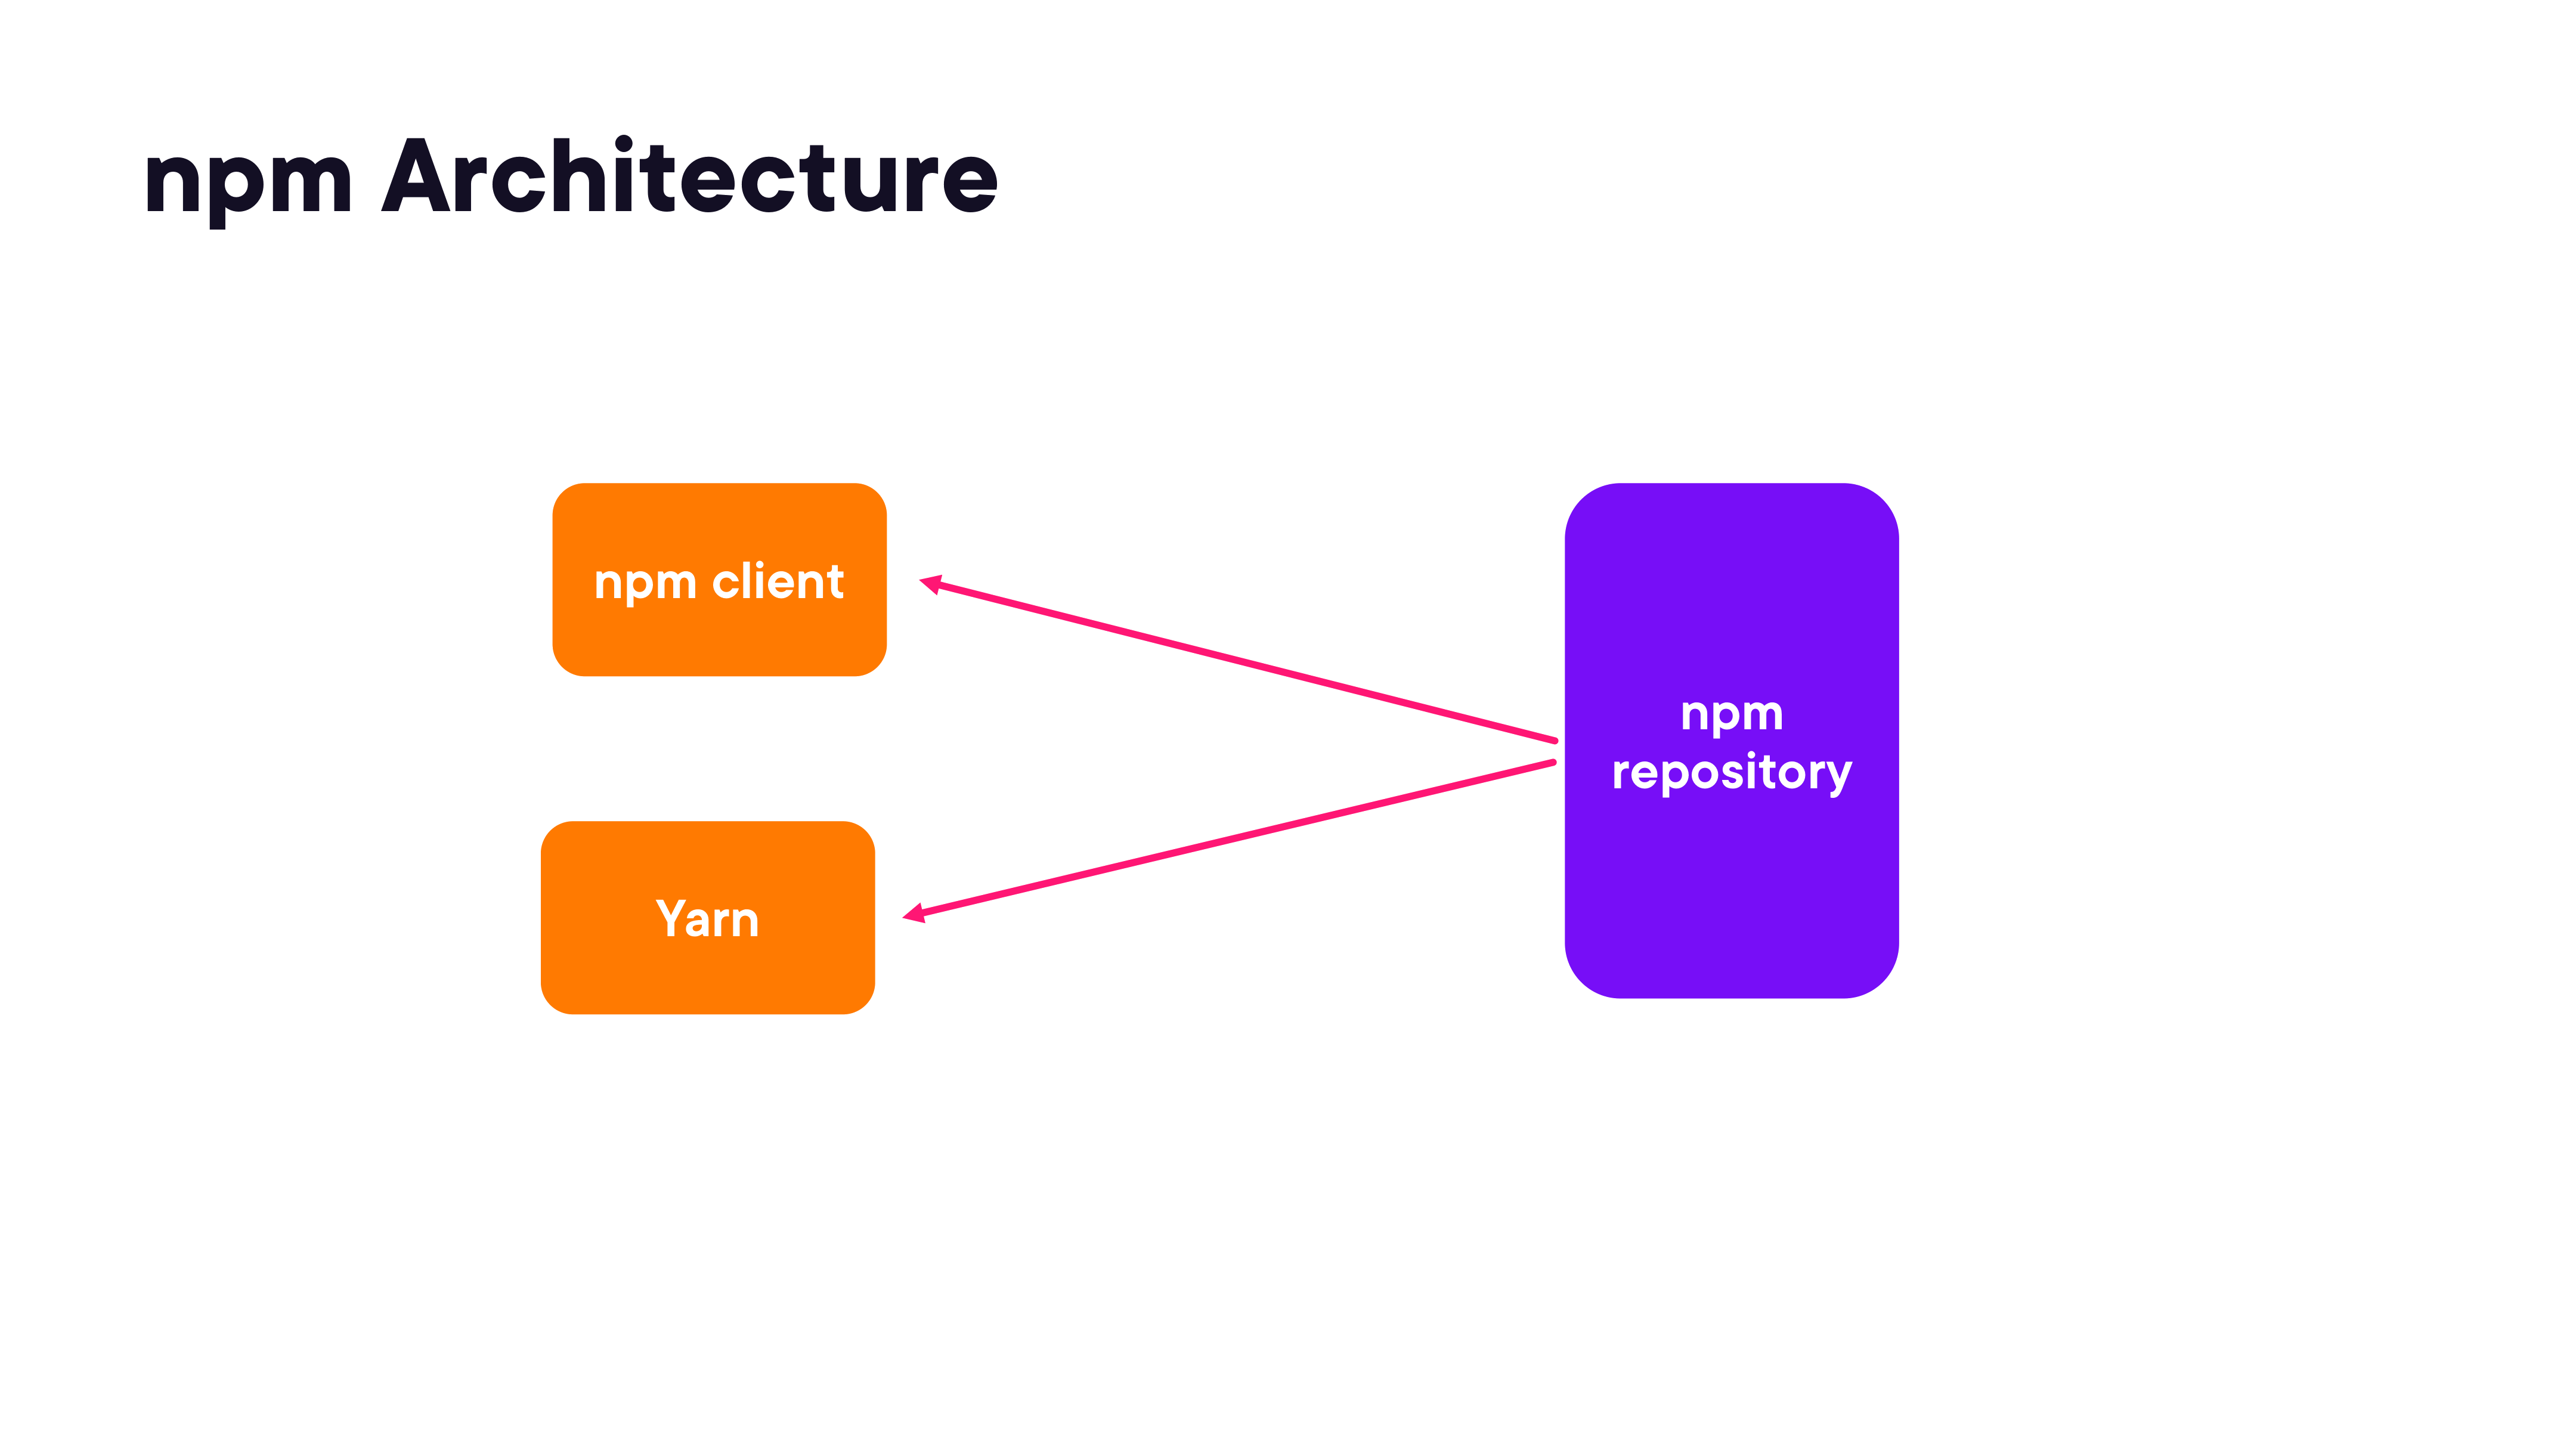

In [2]:
render_diagram(Path("assets/01-npm-architecture.png"))

### Module vs. Package

These two terms are often conflated but have distinct meanings in the Node.js ecosystem:

| Term | Definition |
|---|---|
| **Module** | A single JavaScript file that can be loaded with `require()` or `import` |
| **Package** | A directory containing one or more modules, described by a `package.json` manifest |

Every package can expose one or more modules, but not every module belongs to a package.


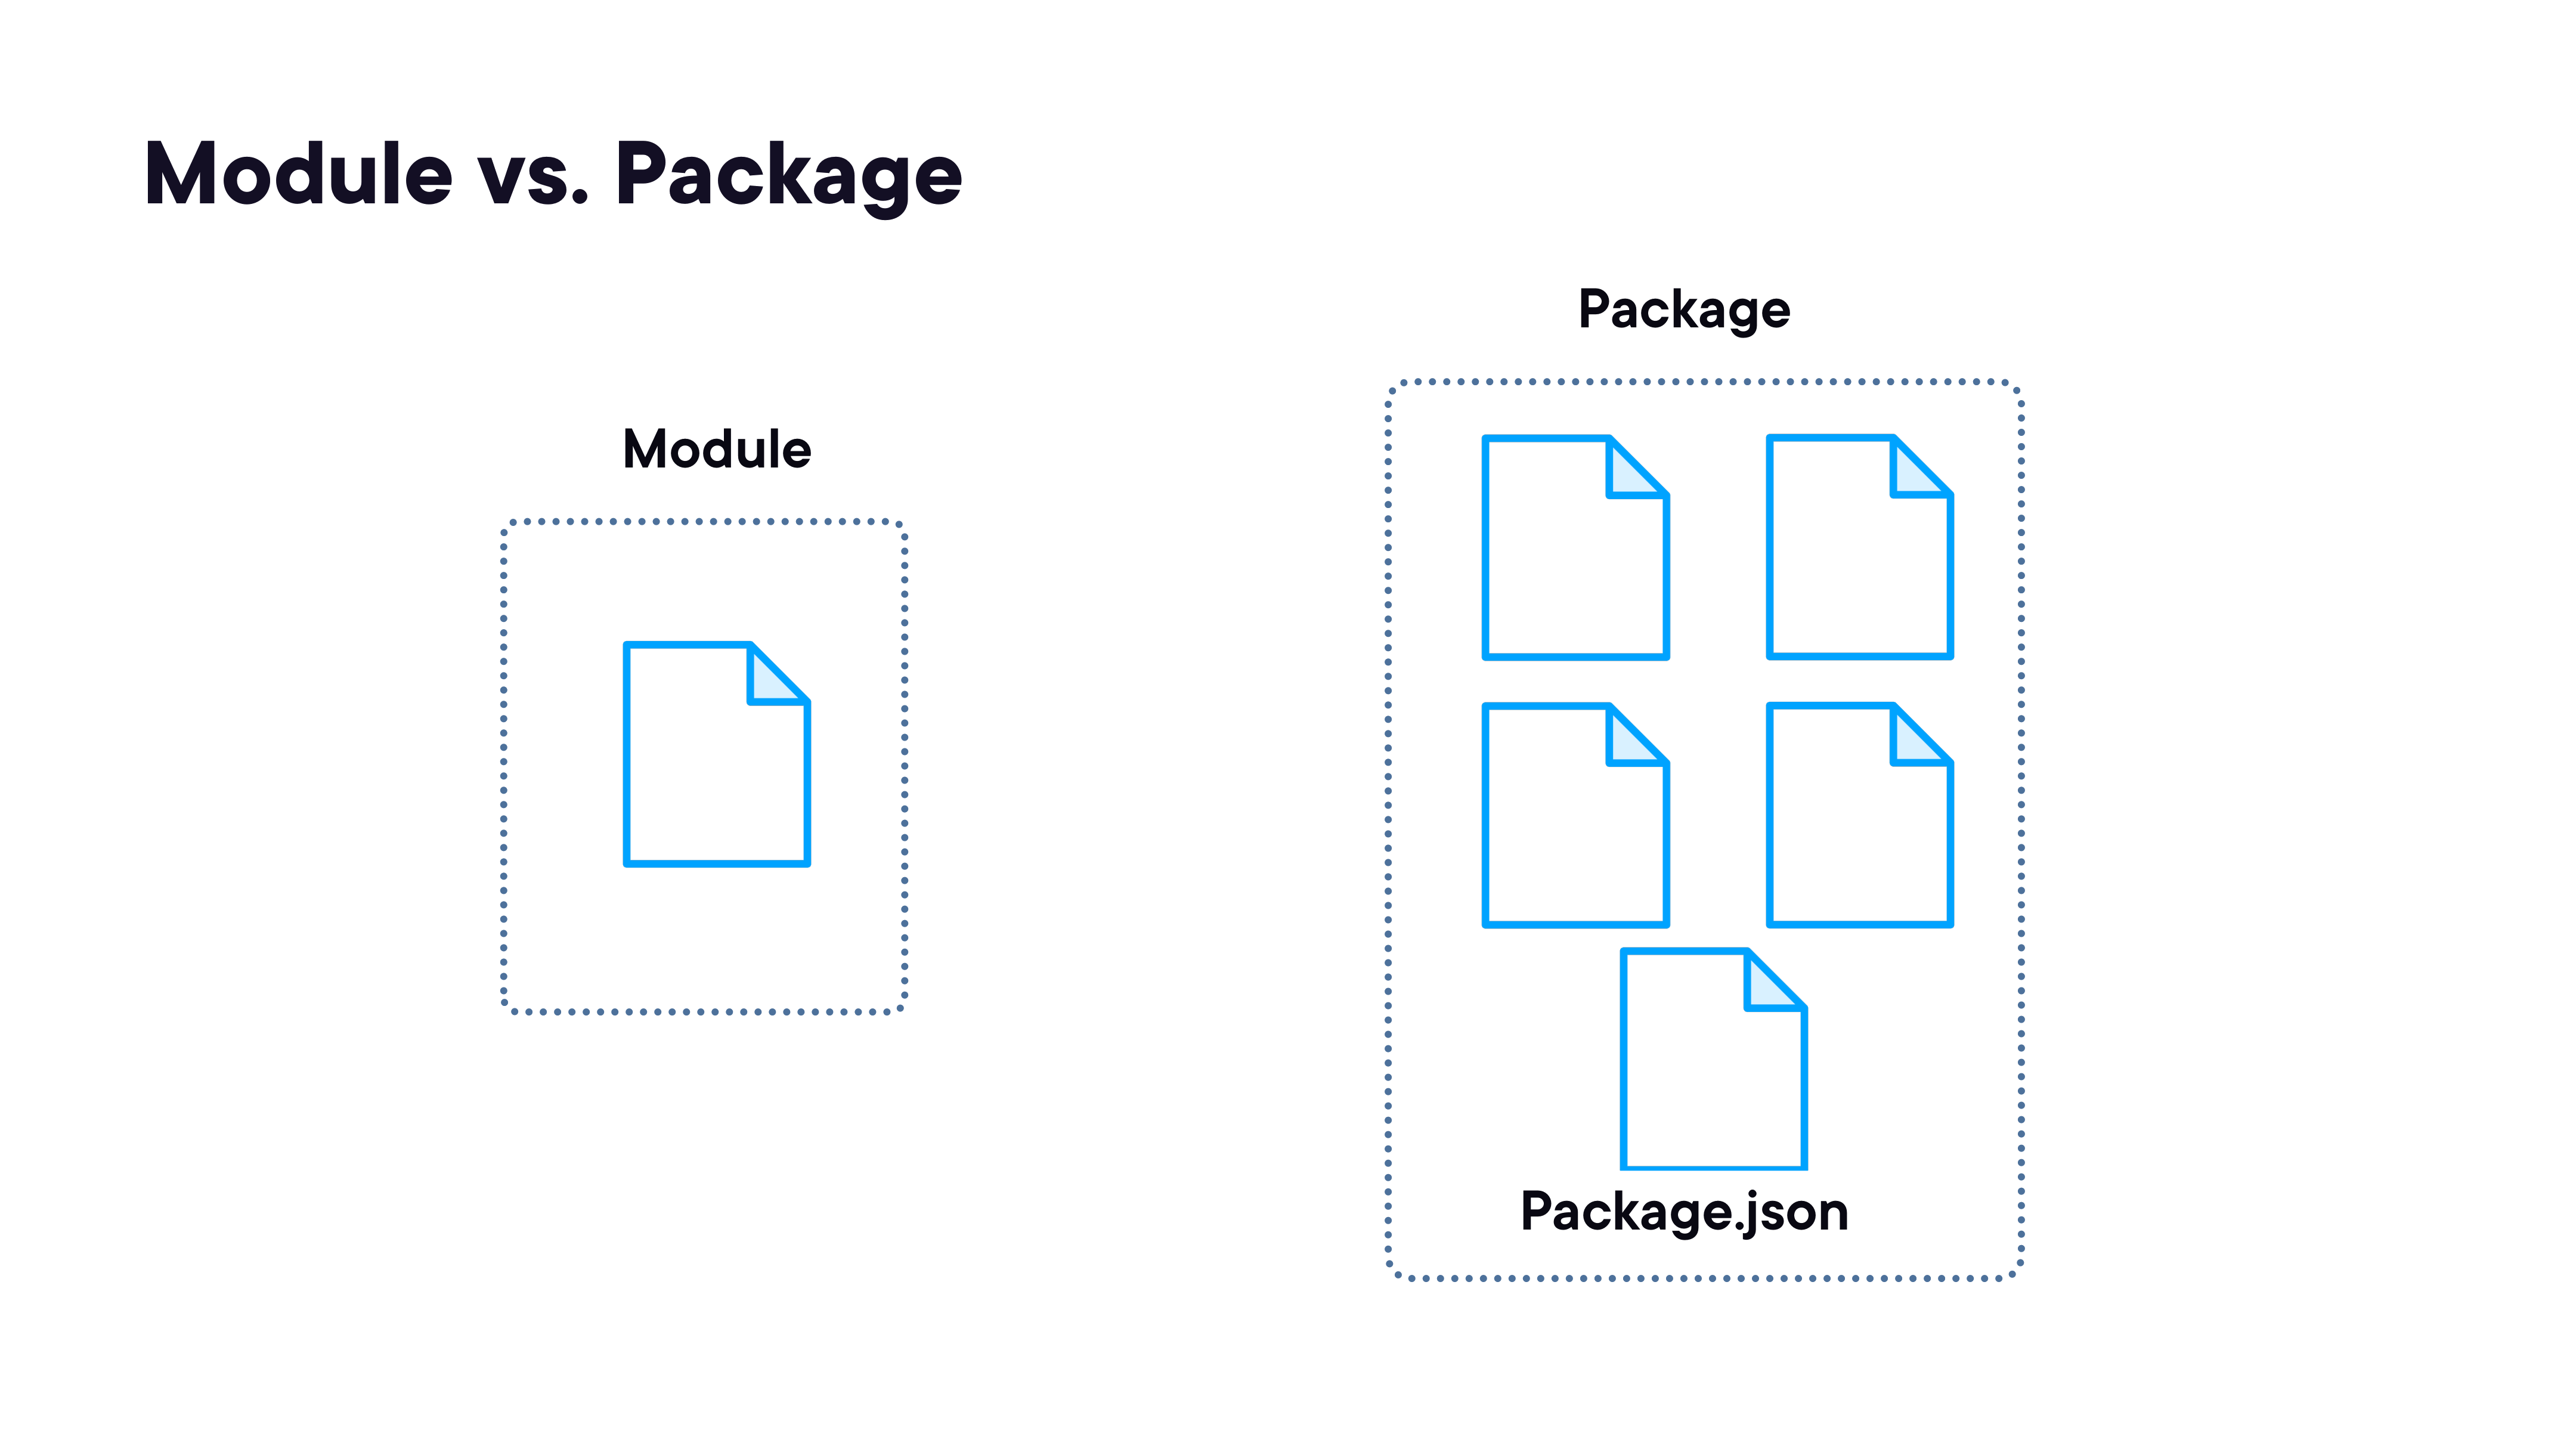

In [3]:
render_diagram(Path("assets/02-module-vs-package.png"))

---
## Module 02: Managing Packages with npm

_Covers the everyday npm workflow: initialising projects, installing and removing packages, understanding `package.json`, and why `package-lock.json` exists._

### Overview

Typical tasks covered:

- Getting help (`npm help`, `npm <command> --help`)
- Installing and removing packages

### Types of npm Projects

npm is used for two fundamentally different project types:

| Project type | Purpose |
|---|---|
| **For Users** | An application consumed by end users (a website, CLI tool, service) — dependencies are installed into `node_modules` |
| **3rd Party Package** | A library meant to be consumed by other developers — published to the npm registry |

### package.json

`package.json` is the manifest for an npm project. It serves two primary purposes:

1. **Track dependencies** — lists all packages your project needs, along with acceptable version ranges, so `npm install` can reconstruct `node_modules` from scratch
2. **Create scripts** — defines shorthand commands (`npm run build`, `npm test`, etc.) that standardise how the project is built, tested, and run

Common commands:

```bash
npm init              # create package.json interactively
npm init -y           # create package.json with defaults
npm install <pkg>     # install and add to dependencies
npm install -D <pkg>  # install and add to devDependencies
npm uninstall <pkg>   # remove package and update package.json
npm run <script>      # execute a script defined in package.json
```

### package-lock.json

`package.json` records version *ranges* (e.g. `^2.1.0`), which means different installs at different times may resolve to different exact versions. This is the **version drift problem**.

`package-lock.json` solves this by recording the *exact* resolved version of every package (and every transitive dependency) at the time of install. When a coworker runs `npm install`, they get identical versions — not just the same range.

**Rule:** always commit `package-lock.json` to version control.


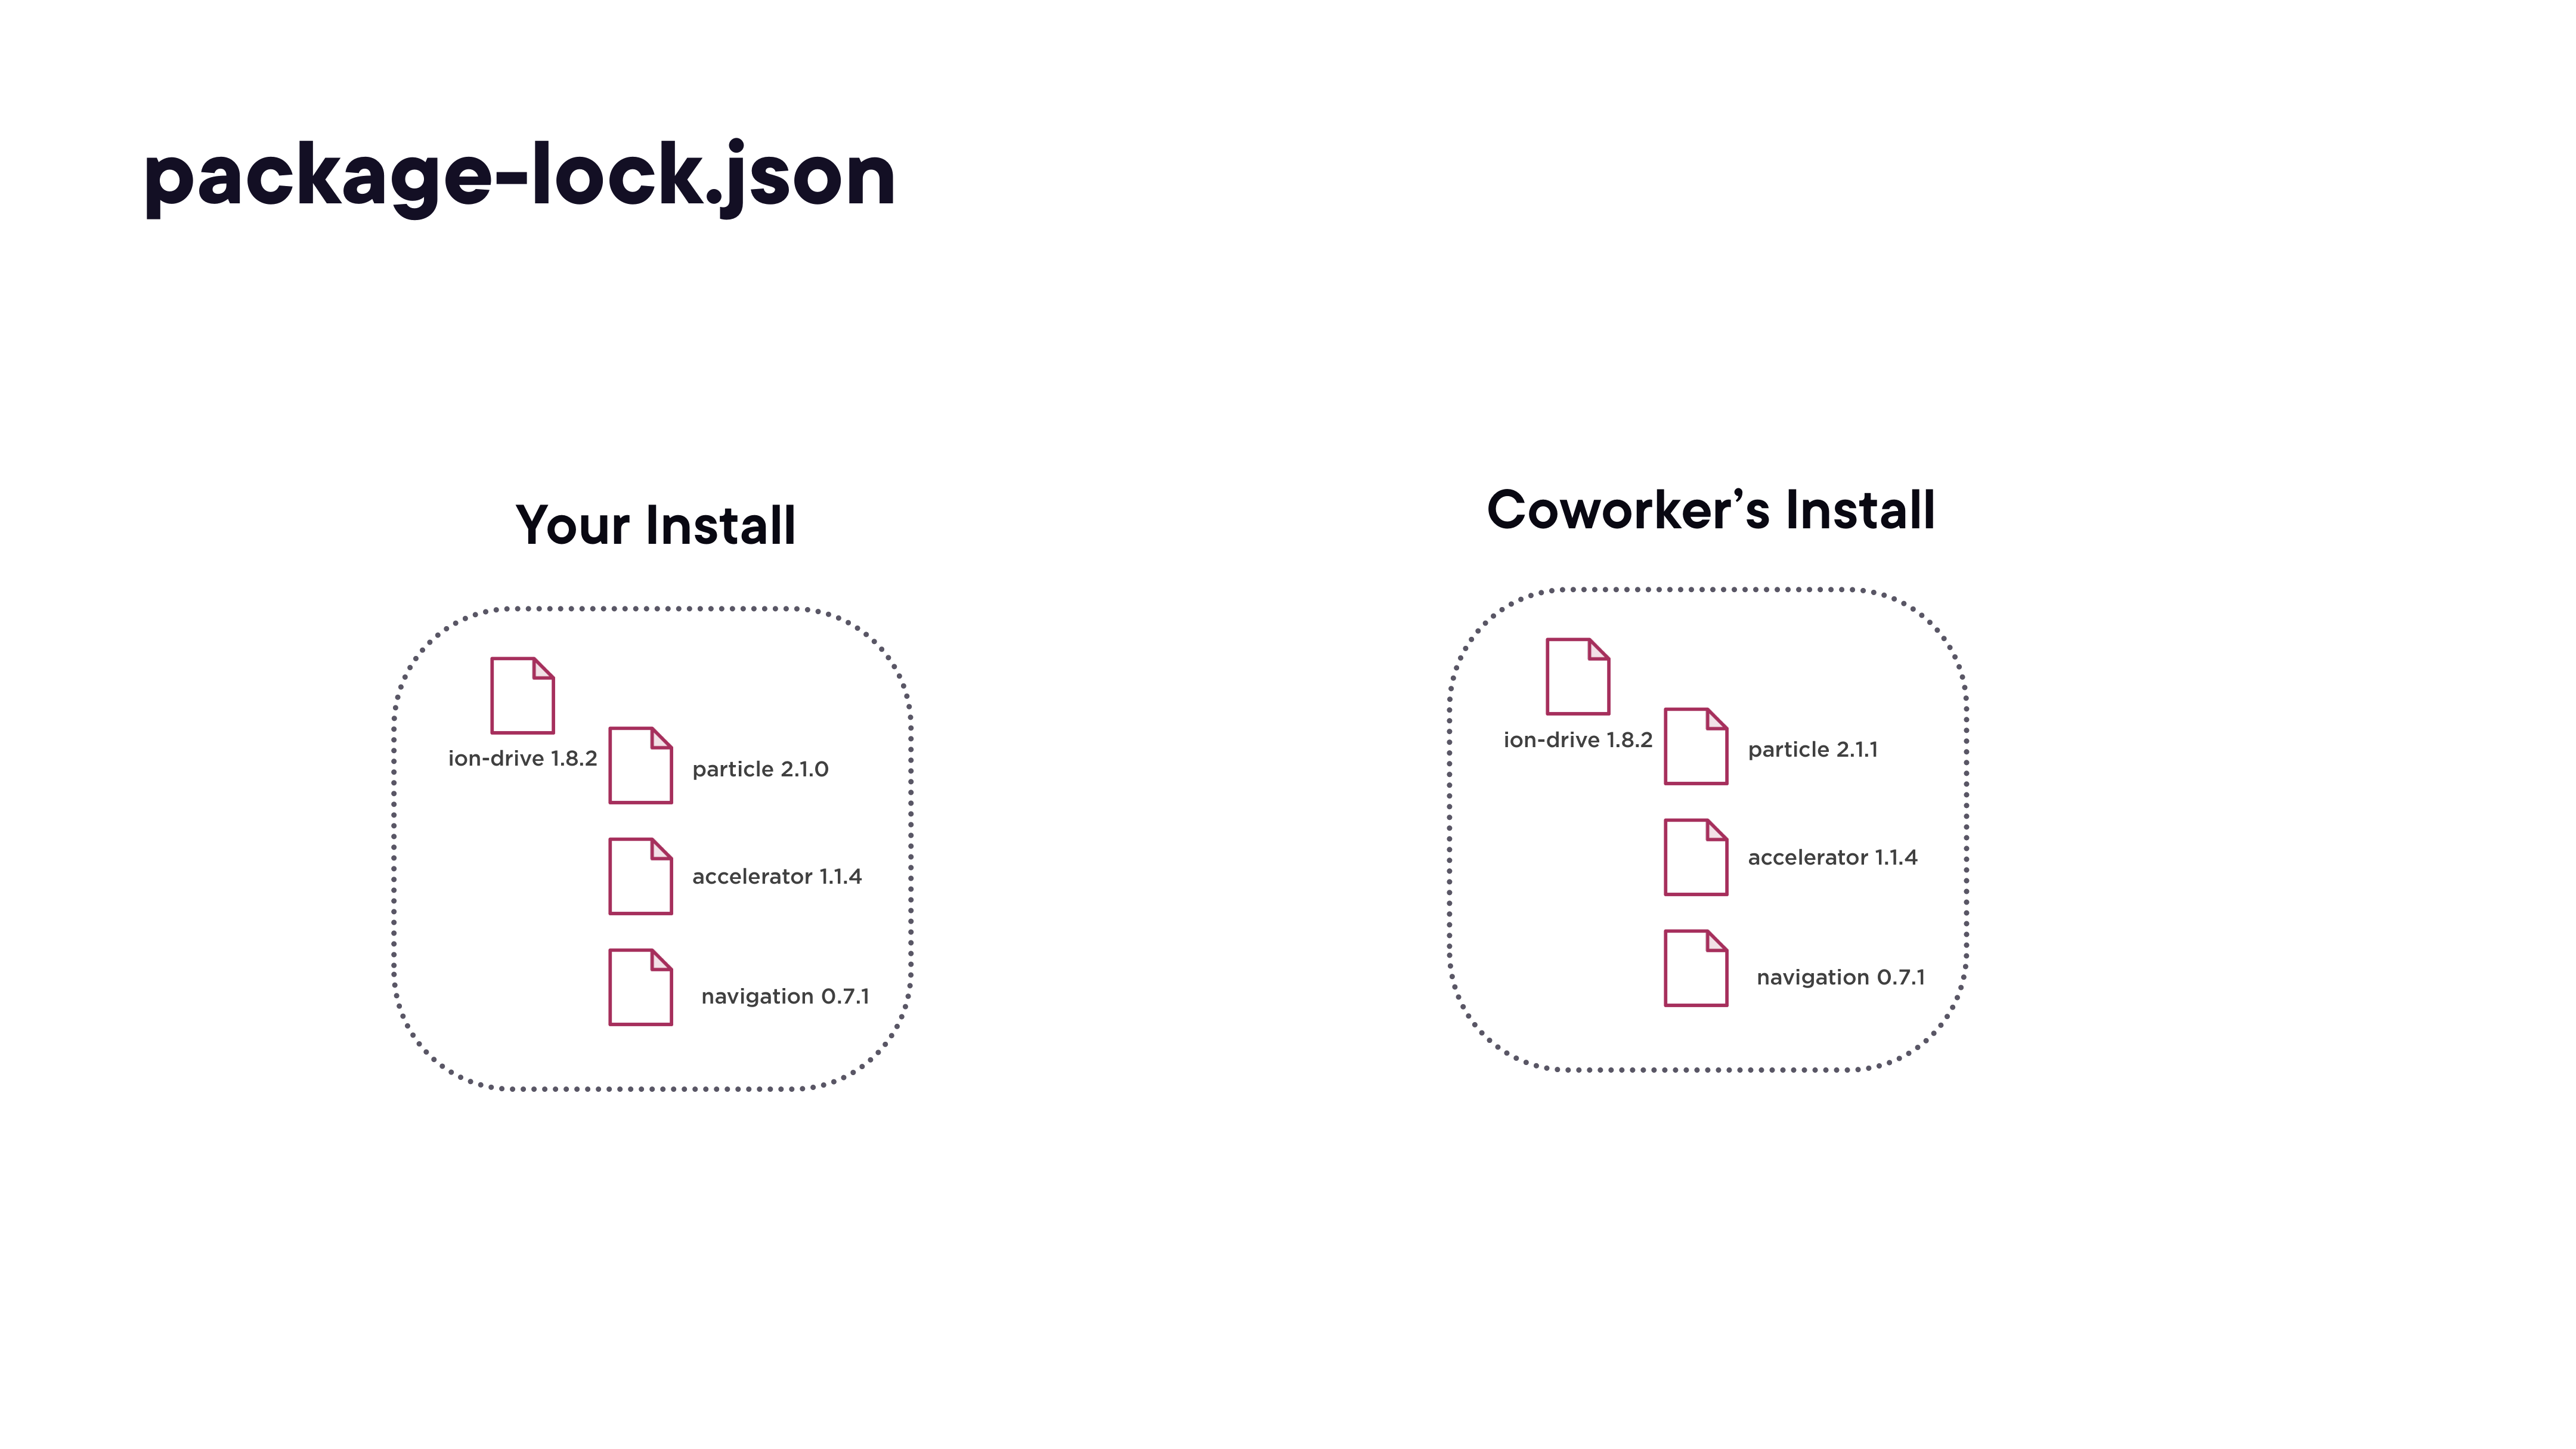

In [4]:
render_diagram(Path("assets/03-package-lock-divergence.png"))

### Considerations with Third-Party Code

The same three concerns apply when installing with npm:

- **Download** — packages are fetched from the npm registry; you can configure a private registry for internal packages
- **Security** — run `npm audit` to surface known vulnerabilities in your dependency tree; use `npm audit fix` to apply safe patches
- **Versioning** — use semantic versioning ranges carefully; commit your lockfile to prevent drift

---
## Module 03: Advanced Tasks with npm

_Goes beyond basic installs: installing from non-registry sources, finding packages, writing scripts, and working with multiple linked projects._

### Overview

Advanced topics covered:

- Installing from other locations
- Finding packages
- Scripts
- Other advanced tasks

### Installing from Other Locations

The npm registry is not the only install source. Common reasons to install from elsewhere:

- **Building a 3rd party package** — install from a local path while developing the package itself
- **Pre-release testing** — install directly from a GitHub branch before the author publishes to npm
- **Customising a package** — install from a fork rather than the official registry entry

```bash
npm install ./local-package          # local directory
npm install github:owner/repo        # GitHub repo
npm install github:owner/repo#branch # specific branch
npm install <tarball-url>            # URL to a .tgz file
```

### Finding Packages

```bash
npm search <term>          # search the registry from the CLI
npm view <pkg>             # show metadata for a package
npm view <pkg> versions    # list all published versions
```

The npm website (npmjs.com) provides richer search with download stats, README previews, and dependency graphs.

### Scripts

The `scripts` field in `package.json` is a key automation mechanism. npm provides lifecycle hooks that run automatically:

```json
{
  "scripts": {
    "preinstall": "echo before install",
    "install":    "echo during install",
    "postinstall": "echo after install",
    "build":  "webpack --config webpack.prod.js",
    "test":   "jest",
    "start":  "node server.js",
    "lint":   "eslint src/"
  }
}
```

Run with `npm run <script-name>`. The special scripts `start`, `test`, and `install` can be run without the `run` keyword.

### Multiple Projects (Local Linking)

When developing a package locally that is consumed by another local project, use `npm link` to avoid constant publish/install cycles:

```bash
# In the dependency project:
npm link

# In the main project:
npm link <dependency-package-name>
```

This creates a symlink so changes in the dependency project are immediately reflected in the consuming project — no re-publish needed.

---
## Module 04: Managing Packages with Yarn

_Covers Yarn's architecture, how it differs from npm, zero-install mode, basic and advanced commands, and what Yarn intentionally does not do._

### Overview

Topics covered:

- Architecture
- Installing Yarn
- Basic tasks
- Scripts
- Advanced tasks
- Publishing
- What Yarn doesn't do

### Why Yarn Exists

Yarn was created to address two core problems with npm's original `node_modules` approach:

- **Compatibility** — npm's flat `node_modules` directory had resolution edge-cases and phantom dependency issues
- **Improve npm: fix `node_modules`** — Yarn 2+ (Berry) replaces `node_modules` with Plug'n'Play (PnP), a resolution strategy that eliminates the directory entirely in favour of a single `.pnp.cjs` resolver file

### The node_modules Problem

`node_modules` directories are notoriously large and slow to install because every project gets its own full copy of every dependency. The file count and size grow dramatically with larger frameworks:

**node_modules (npm install)**

| Package | Files | Size |
|---|---|---|
| Underscore | 508 | 1 MB |
| Express | 425 | 2.7 MB |
| Angular | 43,025 | 289 MB |

**Yarn cache (equivalent packages)**

| Package | Files | Size |
|---|---|---|
| Underscore | 2 | 371 KB |
| Express | 58 | 840 KB |
| Angular | 867 | 73 MB |

Yarn stores packages as compressed archives in a global cache (`~/.yarn/cache`), dramatically reducing both file count and disk usage.


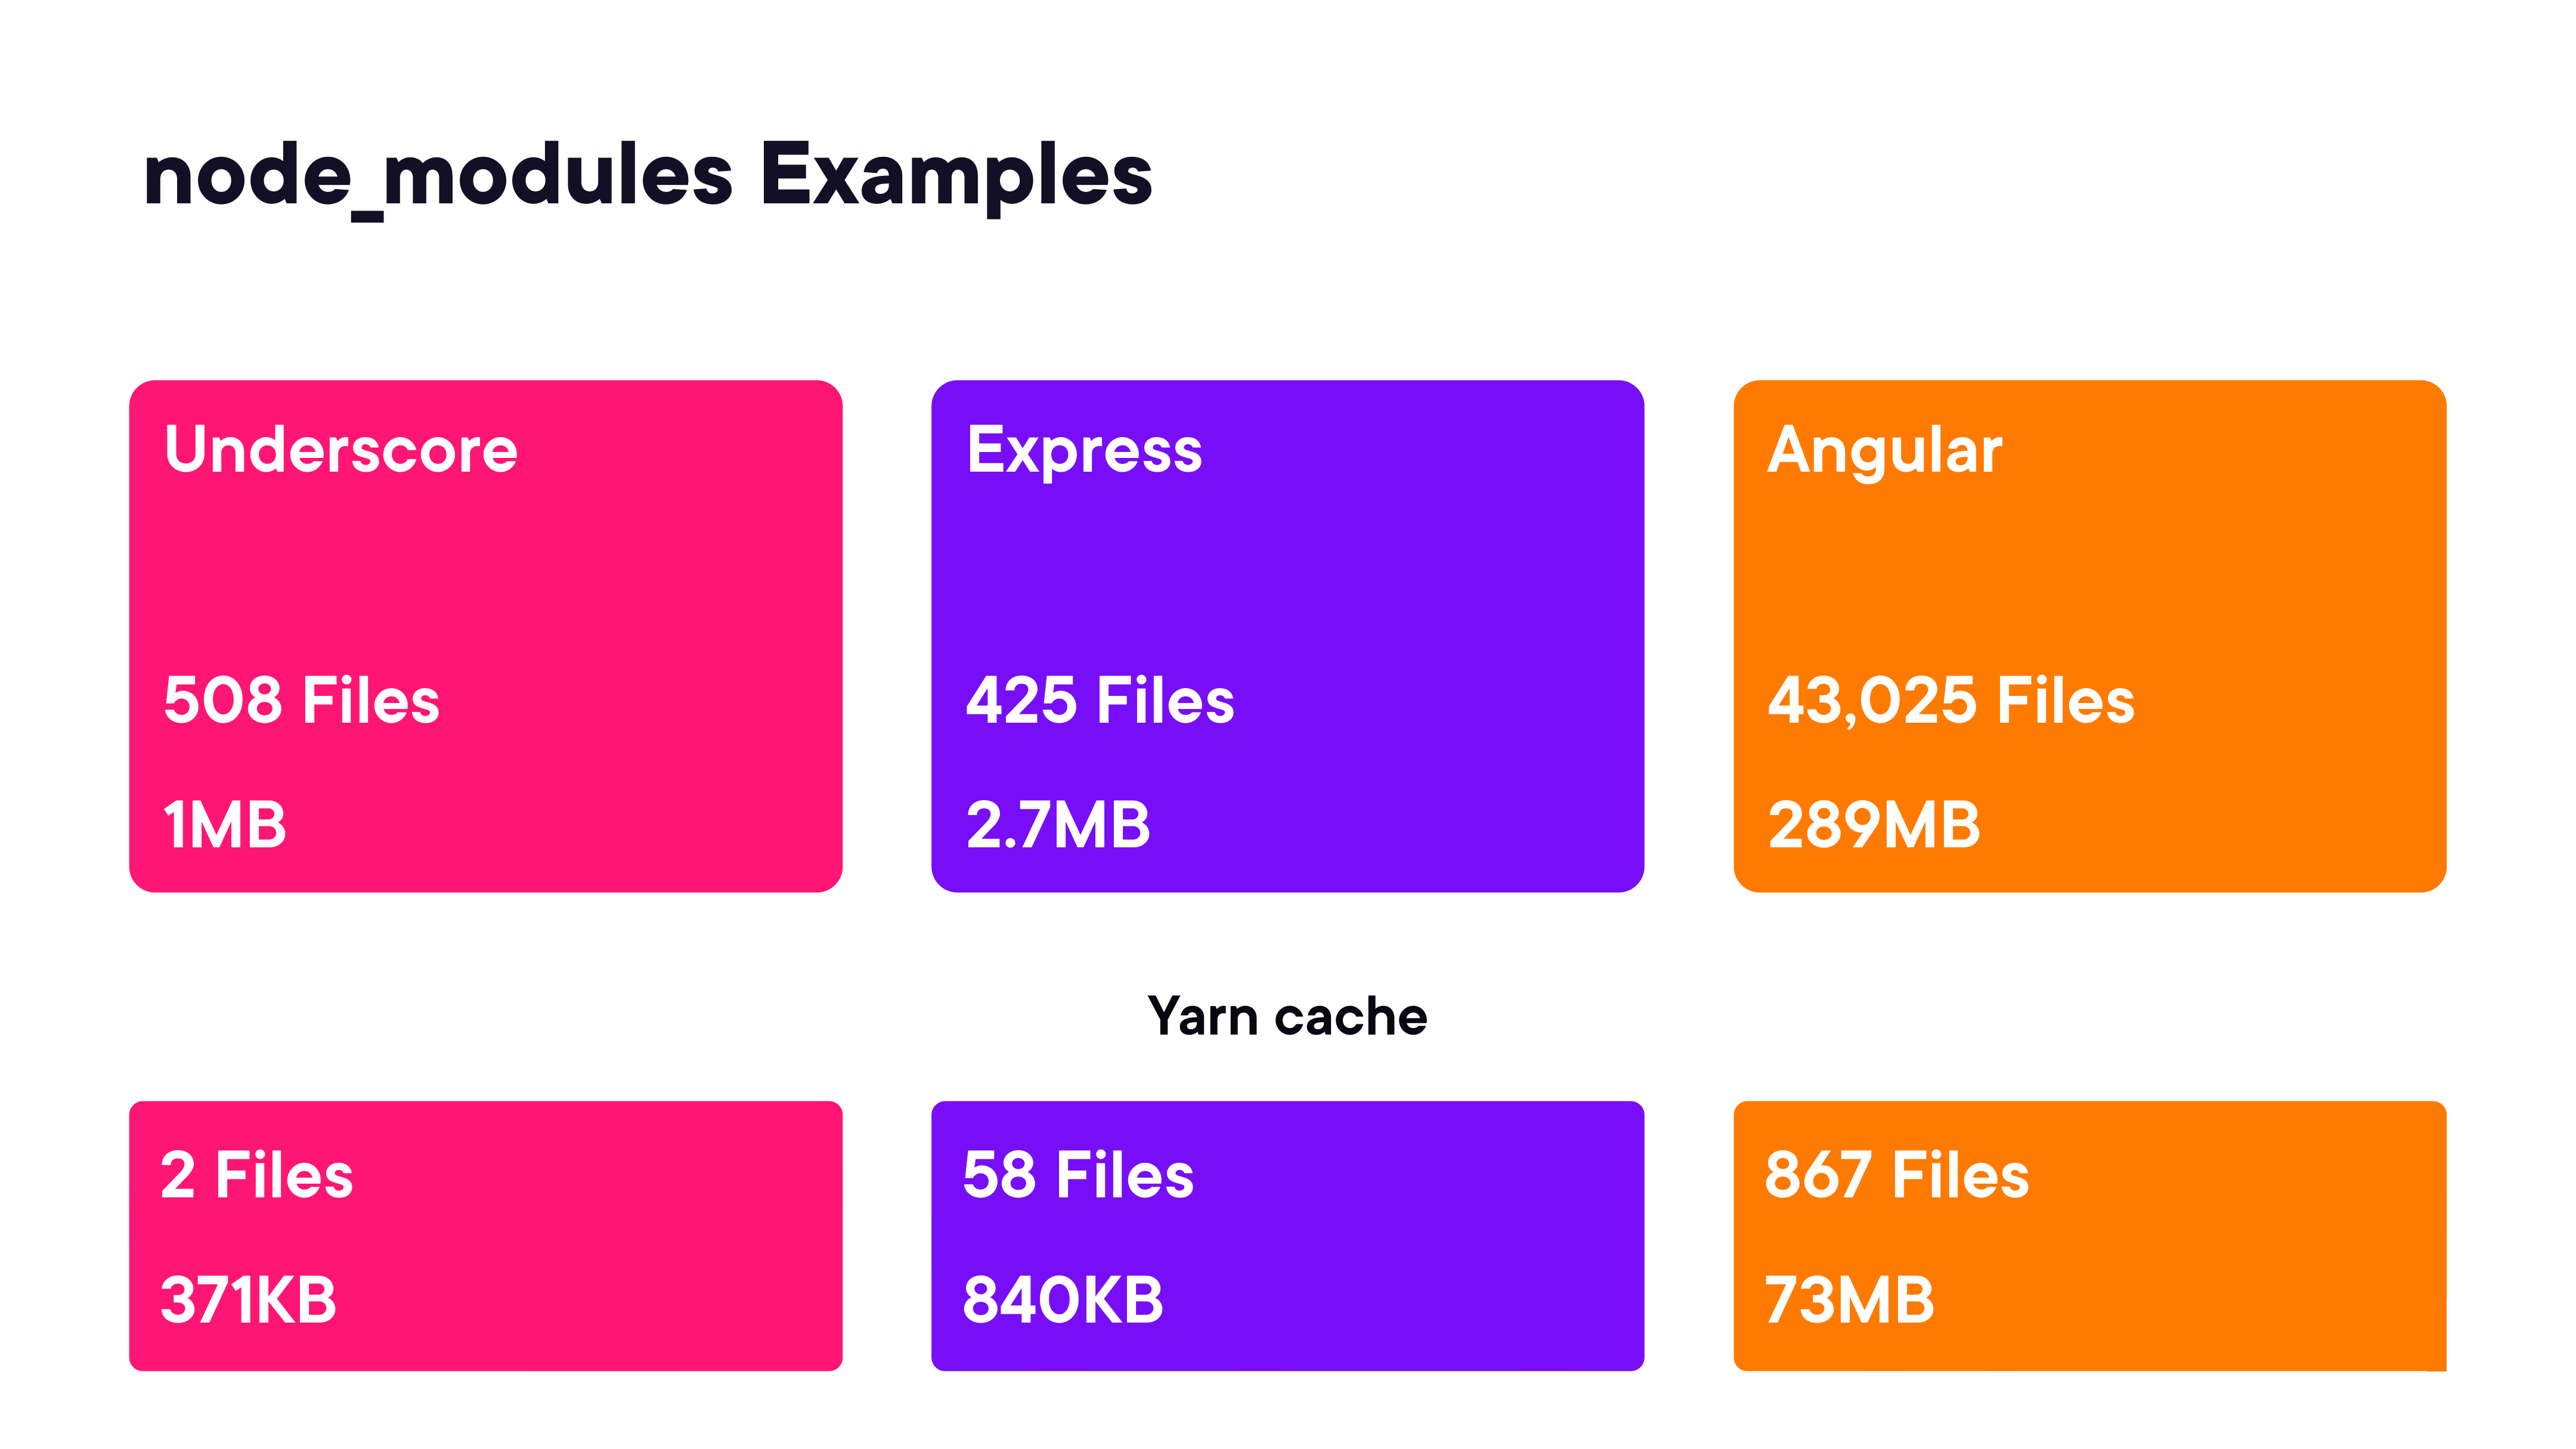

In [5]:
render_diagram(Path("assets/04-node-modules-vs-yarn-cache.png"))

### Zero Install

Yarn's **Zero Install** feature takes the cache-based approach further:

- **Check in `.yarn/cache`** — commit the compressed package archives directly to your repository
- **Download and run** — after cloning, the project works immediately without running `yarn install` at all

This makes CI faster (no network fetch needed), ensures every environment is byte-for-byte identical, and eliminates the risk of a package disappearing from the registry.

### Installing Yarn

Yarn 2+ (Berry) is managed per-project via Corepack, which ships with Node.js 16+:

```bash
corepack enable              # enable Corepack (once per machine)
yarn init -2                 # initialise a new project with Yarn Berry
yarn set version stable      # upgrade existing project to latest stable
```

The Yarn binary for the project is stored in `.yarn/releases/` and committed to the repo, so all collaborators use exactly the same version.

### Basic Yarn Commands

```bash
yarn                        # install all dependencies (equivalent to npm install)
yarn add <pkg>              # install and add to dependencies
yarn add -D <pkg>           # install and add to devDependencies
yarn remove <pkg>           # uninstall and remove from package.json
yarn up <pkg>               # upgrade a package
yarn info <pkg>             # show package metadata
```

### Scripts with Yarn

Yarn uses the same `scripts` field in `package.json` as npm:

```bash
yarn build          # runs the "build" script
yarn test           # runs the "test" script
yarn run <script>   # explicit form for any script
```

Unlike npm, Yarn does not require `run` for custom script names — `yarn build` works without `yarn run build`.

### Advanced Yarn Tasks

Yarn supports the same non-registry install sources as npm:

```bash
yarn add ./local-package              # local path
yarn add owner/repo                   # GitHub repo
yarn add https://example.com/pkg.tgz  # tarball URL
```

Yarn also supports **workspaces** — a first-class monorepo feature that links multiple packages within a single repository and hoists shared dependencies.

### Publishing with Yarn

```bash
yarn npm publish            # publish the package to the npm registry
yarn npm publish --access public  # required for scoped packages
yarn version patch          # bump patch version (1.0.0 → 1.0.1)
yarn version minor          # bump minor version (1.0.0 → 1.1.0)
```

Yarn publishes to the same npm registry, so packages published with Yarn are installable with npm and vice versa.

### What Yarn Doesn't Do

Several npm features that may seem missing from Yarn are intentional design decisions:

- **Listing globally installed packages** — Yarn discourages global installs; use `yarn dlx` for one-off executions instead
- **Global installs** — `yarn global` was removed in Yarn 2+; the recommended alternative is per-project tooling or `yarn dlx`
- **Pruning** — Yarn's PnP mode eliminates the concept of orphaned `node_modules` entries entirely, making pruning unnecessary

---
## Summary

| Topic | Key takeaway |
|---|---|
| Package managers | Automate download, versioning, and linking of third-party code |
| npm registry | Shared by both npm client and Yarn — one registry, two clients |
| package.json | Declares dependency ranges and scripts |
| package-lock.json | Pins exact resolved versions — always commit it |
| npm scripts | Lifecycle hooks + custom commands standardise project operations |
| npm link | Local development workflow for multi-package projects |
| Yarn Berry | Replaces node_modules with PnP, uses compressed cache |
| Zero Install | Commit `.yarn/cache` → no `yarn install` needed after clone |